In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Для регрессии
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Для классификации и ROC-кривой
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

# Загрузка данных
df = pd.read_csv('processed_spotify_data.csv')

# Визуальный осмотр
df.head()

,duration_ms,popularity,danceability,energy,key,loudness,mode,instrumentalness,tempo,stream_count,...,key_name_D#,key_name_E,key_name_F,key_name_F#,key_name_G,key_name_G#,mode_name_Minor,release_quarter_Q2,release_quarter_Q3,release_quarter_Q4
0,169594,47,0.6777,0.7949,9,-2.90,1,0.0065,111.89,46592,...,False,False,False,False,False,False,False,False,False,True
1,256755,26,0.9405,0.7163,1,-7.72,1,0.0198,129.17,5374,...,False,False,False,False,False,False,False,False,False,True
2,170212,46,0.6853,0.9500,4,-2.38,1,0.0103,150.06,218262,...,False,True,False,False,False,False,False,False,False,True
3,181250,4,0.7817,0.6943,6,-8.00,1,0.0151,121.16,5248,...,False,False,False,True,False,False,False,True,False,False
4,160894,27,0.7200,0.4958,1,-6.38,1,0.0372,104.16,27420,...,False,False,False,False,False,False,False,False,False,False


In [12]:
# Выбираем целевую переменную
target_reg = 'popularity'

# Удаляем целевую переменную и её производные из признаков
X_reg = df.drop(columns=[target_reg, 'popularity_category_Low', 'popularity_category_Medium', 'popularity_category_Very High'])
y_reg = df[target_reg]

# Разделение на обучающую и тестовую выборки
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Создание и обучение модели дерева решений
# Ограничим глубину дерева, чтобы избежать переобучения
dt_regressor = DecisionTreeRegressor(max_depth=5, random_state=42)
dt_regressor.fit(X_train_reg, y_train_reg)

# Предсказание
y_pred_reg = dt_regressor.predict(X_test_reg)

# Оценка качества
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"Регрессия (Дерево решений):")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R2-score: {r2:.2f}")

# Попробуйте изменить max_depth (например, на 3, 7 или 10) и посмотрите, как меняются метрики.

Регрессия (Дерево решений):
MSE: 50.39
RMSE: 7.10
MAE: 5.64
R2-score: 0.80


Порог популярности (медиана): 26.0
Classification Report (Популярность):
              precision    recall  f1-score   support

           0       0.54      0.79      0.64      4909
           1       0.63      0.34      0.44      5091

    accuracy                           0.56     10000
   macro avg       0.58      0.57      0.54     10000
weighted avg       0.58      0.56      0.54     10000



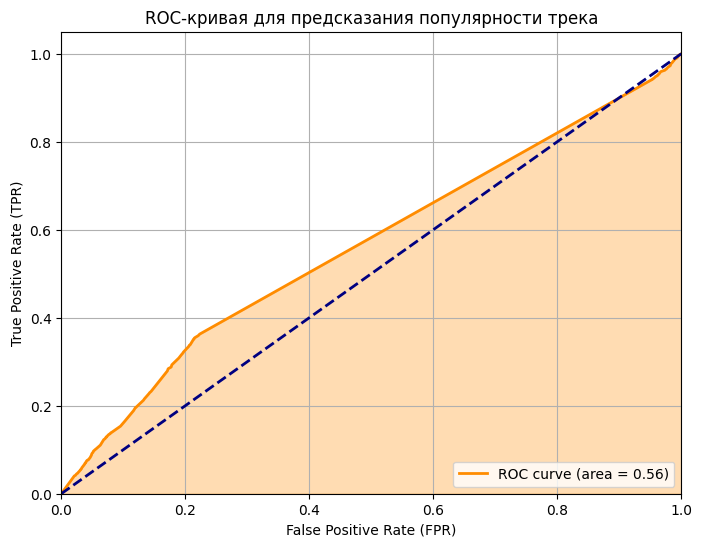

In [17]:
# 1. Создаем новый бинарный признак (целевую переменную)
# Берем медиану популярности, чтобы классы были сбалансированы
median_pop = df['popularity'].median()
df['is_popular'] = (df['popularity'] >= median_pop).astype(int)

# 2. Убираем признаки, которые напрямую выдают ответ (утечка данных)
cols_to_drop = [
    'popularity', 'is_popular', 
    'popularity_category_Low', 'popularity_category_Medium', 'popularity_category_Very High',
    'stream_count', 'log_stream_count' 
]

X_clf = df.drop(columns=cols_to_drop)
y_clf = df['is_popular']

# 3. Разделение на обучающую и тестовую выборки
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42)

# 4. Обучение модели Дерева Решений
# Увеличим глубину до 10 и используем criterion='entropy' (как в методичке для ID3/C4.5)
# Увеличиваем глубину до 15, но ставим min_samples_leaf=10, чтобы дерево не запоминало шум
dt_classifier = DecisionTreeClassifier(
    max_depth=15, 
    min_samples_leaf=10, 
    criterion='entropy', 
    random_state=42
)
dt_classifier.fit(X_train_clf, y_train_clf)

# 5. Предсказание классов и вероятностей
y_pred_clf = dt_classifier.predict(X_test_clf)
y_proba_clf = dt_classifier.predict_proba(X_test_clf)[:, 1]

# 6. Вывод метрик
print(f"Порог популярности (медиана): {median_pop}")
print("Classification Report (Популярность):")
print(classification_report(y_test_clf, y_pred_clf))

# 7. Построение красивой ROC-кривой
fpr, tpr, thresholds = roc_curve(y_test_clf, y_proba_clf)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
# Рисуем линию
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
# Закрашиваем площадь под кривой
plt.fill_between(fpr, tpr, alpha=0.3, color='darkorange')
# Линия случайного угадывания
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') 

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривая для предсказания популярности трека')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()